In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
BASE_DIR = Path.cwd()
data_path = Path.cwd() / "data" / "emg_data_fist_rest.txt"

signal = np.loadtxt(data_path)
print(signal)

[-23.07 -26.2  -29.33 ... -30.53 -28.91 -28.35]


In [5]:
sampling_rate = 1000 #Hz
duration = len(signal)/sampling_rate
print(f"The duration of this recording is {duration} seconds.")

The duration of this recording is 36.439 seconds.


In [6]:
fist_intervals = []
rest_intervals = []

for i in range(3,36,4):
    fist_intervals.append((i, i+2))
    rest_intervals.append((i-2, i))

print(f"Fist intervasl: {fist_intervals}")
print(f"Rest intervals: {rest_intervals}")

Fist intervasl: [(3, 5), (7, 9), (11, 13), (15, 17), (19, 21), (23, 25), (27, 29), (31, 33), (35, 37)]
Rest intervals: [(1, 3), (5, 7), (9, 11), (13, 15), (17, 19), (21, 23), (25, 27), (29, 31), (33, 35)]


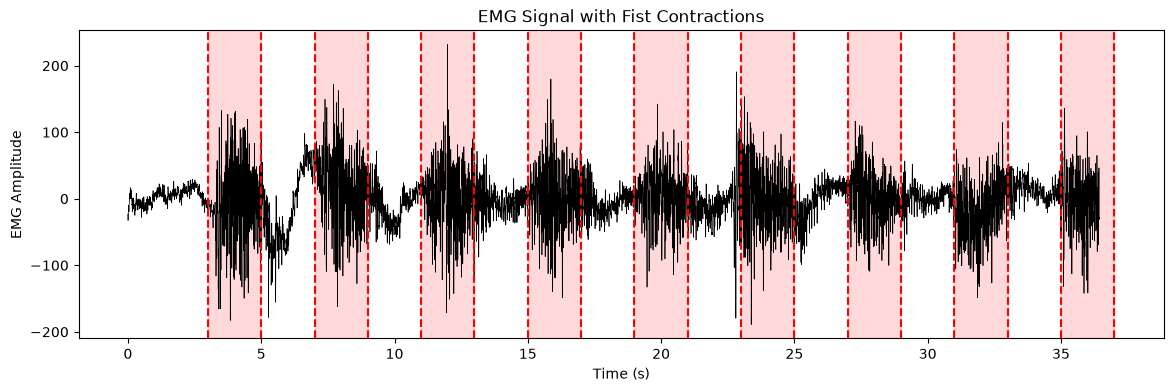

In [7]:
time = np.arange(len(signal))/sampling_rate


fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(time, signal, linewidth=0.5, color="black")

for start, end in fist_intervals:
    ax.axvline(start, color="red", linestyle="--")
    ax.axvline(end, color="red", linestyle="--")

    ax.axvspan(start, end, color="red", alpha=0.15)

ax.set_xlabel("Time (s)")
ax.set_ylabel("EMG Amplitude")
ax.set_title("EMG Signal with Fist Contractions")

plt.show()

In [8]:
def segmentation(signal, sampling_rate, fist_intervals, rest_intervals, window_ms = 200):
    window_samples = sampling_rate * window_ms / 1000

    segments = []
    lables = []

    for start_index in (0, len(signal) - window_samples, window_samples):
        end_index = start_index + window_samples
        segments.append((start_index, end_index))

    return segments


segments = segmentation(signal, sampling_rate, fist_intervals, rest_intervals, window_ms = 200)
print(segments)
print(len(segments))

[(0, 200.0), (36239.0, 36439.0), (200.0, 400.0)]
3


In [9]:
window_ms = 50
window_samples = int(sampling_rate * window_ms / 1000)

segments = []
labels = []

for start_idx in range(0, len(signal) - window_samples + 1, window_samples):

       end_idx = start_idx + window_samples
       
       start_time = start_idx / sampling_rate
       end_time = end_idx / sampling_rate    

       for start, end in rest_intervals:
        if start_time >= start and end_time < end:
            labels.append(0)
            segments.append(signal[start_idx:end_idx])
            break

       for start, end in fist_intervals:
        if start_time > start and end_time <= end:
            labels.append(1)
            segments.append(signal[start_idx:end_idx])
            break

print(len(segments), len(labels))

690 690


In [10]:
def zero_crossing(signal):    
    count = 0
    for i in range(len(signal)-1):

        if signal[i]*signal[i+1] < 0:
            count += 1

    return count

def signal_power(signal):
    return np.mean(signal ** 2)

zc = []
power = []

for segment in segments:
    zc.append(zero_crossing(segment))
    power.append(signal_power(segment))

print(len(zc), len(power))

690 690


In [11]:
df = pd.DataFrame({

    "zero-crossing": zc, 
    "average-power": power, 
    "label": labels
    
    })

print(df.head(10))

   zero-crossing  average-power  label
0              0      54.028168      0
1              2      95.711004      0
2              0     159.256266      0
3              0     189.744892      0
4              0     163.893236      0
5              0      41.357032      0
6              2     133.434752      0
7              3      97.929358      0
8              4      14.325816      0
9              3      57.290326      0


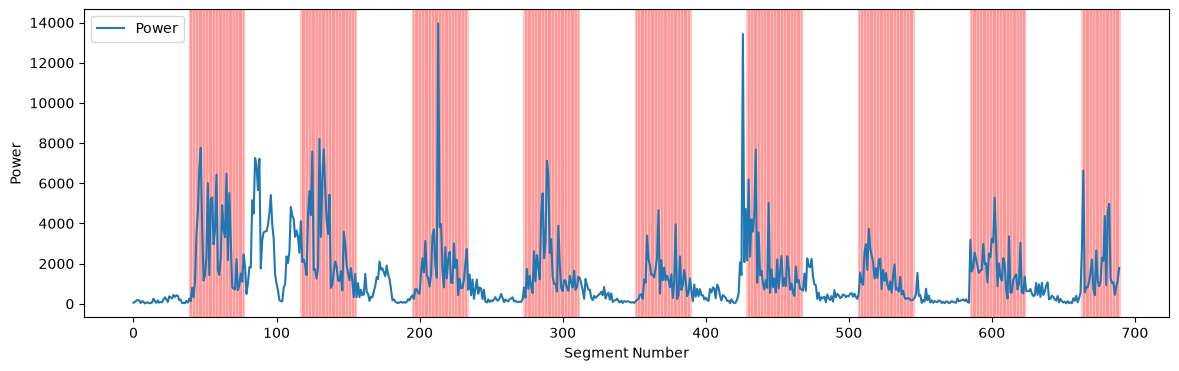

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(df.index, df["average-power"], label="Power")

for i in range(len(df)):
    if df["label"].iloc[i] == 1:
        ax.axvspan(i - 0.5, i + 0.5, color="red", alpha=0.15)

ax.set_xlabel("Segment Number")
ax.set_ylabel("Power")
ax.legend()
plt.show()


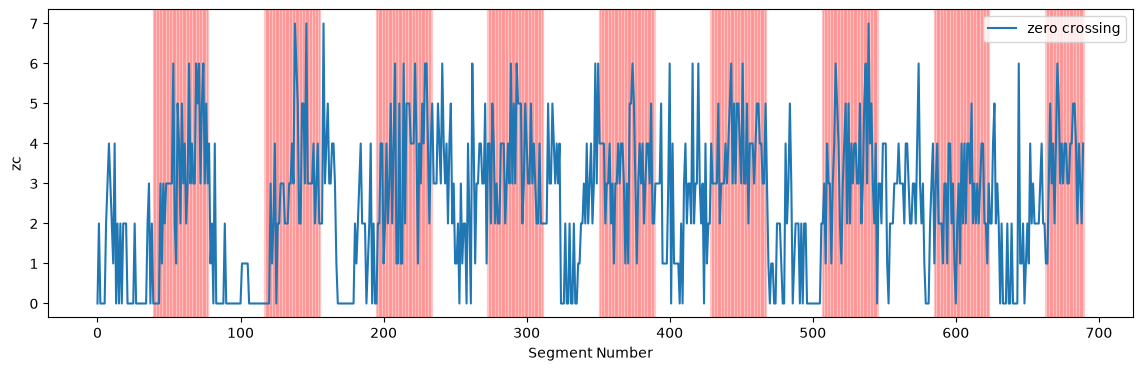

In [13]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(df.index, df["zero-crossing"], label="zero crossing")

for i in range(len(df)):
    if df["label"].iloc[i] == 1:
        ax.axvspan(i - 0.5, i + 0.5, color="red", alpha=0.15)

ax.set_xlabel("Segment Number")
ax.set_ylabel("zc")
ax.legend()
plt.show()


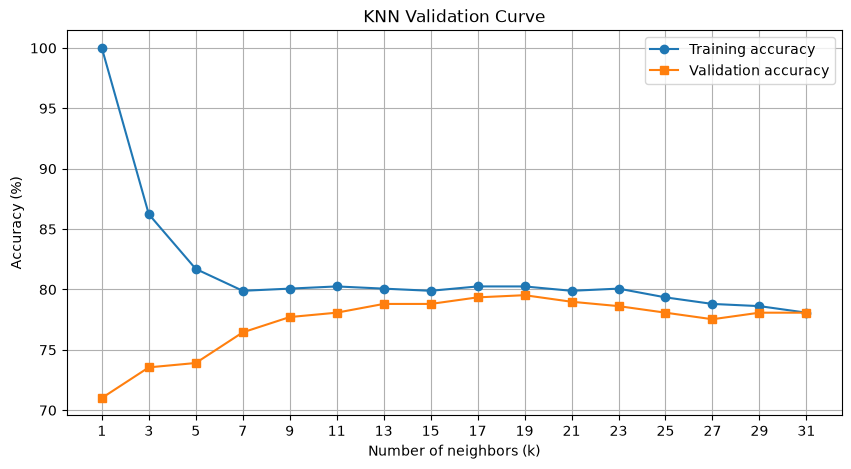

Best k: 19
Best validation accuracy: 79.52898550724638
Final test accuracy: 78.98550724637681


In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

df_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42
)

n_neighbors = list(range(1, 32, 2))

accuracy_train = []
accuracy_validation = []

features = ["zero-crossing", "average-power"]

for i in n_neighbors:
    true_count = 0

    # Manual Leave-One-Out Cross-Validation
    for j in range(len(df_train)):

        test_data_point = df_train.iloc[[j]]
        df_cv = df_train.drop(df_train.index[j])

        X = df_cv[features]
        y = df_cv["label"]

        model = KNeighborsClassifier(n_neighbors=i)
        model.fit(X, y)

        predict = model.predict(test_data_point[features])

        if predict[0] == test_data_point["label"].iloc[0]:
            true_count += 1

    # Validation accuracy
    acc = true_count / len(df_train) * 100
    accuracy_validation.append(acc)

    # Train on the entire training dataset
    model = KNeighborsClassifier(n_neighbors=i)
    model.fit(df_train[features], df_train["label"])

    # Training accuracy
    predict_train = model.predict(df_train[features])

    acc = accuracy_score(
        df_train["label"], predict_train
    ) * 100

    accuracy_train.append(acc)


# Plot validation curve
plt.figure(figsize=(10, 5))

plt.plot(n_neighbors, accuracy_train,
         marker="o", label="Training accuracy")

plt.plot(n_neighbors, accuracy_validation,
         marker="s", label="Validation accuracy")

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Accuracy (%)")
plt.title("KNN Validation Curve")
plt.xticks(n_neighbors)
plt.legend()
plt.grid()
plt.show()


# Find the best k
best_k = n_neighbors[
    accuracy_validation.index(max(accuracy_validation))
]

print("Best k:", best_k)
print("Best validation accuracy:", max(accuracy_validation))


# Final evaluation on unseen test data
model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(df_train[features], df_train["label"])

predict_final = model.predict(df_test[features])

test_accuracy = accuracy_score(
    df_test["label"], predict_final
) * 100

print("Final test accuracy:", test_accuracy)